# Enflasyon ortalaması neyi saklıyor? Analiz defteri

**Çalışma sorusu:** Aralık 2020'den bugüne hangi harcama kalemlerinin fiyatı genel enflasyonun en çok üzerinde arttı, bu kalemler bütçede ne kadar yer tutuyor?

**Veri:** TÜİK Tüketici Fiyat Endeksi (TÜFE), 13 ana harcama grubu + genel endeks, aylık, Ocak 2005 – Eylül 2026. Kaynak: <https://data.tuik.gov.tr>, erişim 14 Ekim 2026.

**Akış:** veri yükleme → temizleme → keşifsel analiz → bulgular → doğrulama → sitede kullanılan özet dosyaların üretimi ve dışa aktarımı.

> Not: Bu defter yukarıdan aşağıya, hatasız çalışacak şekilde yazıldı (Restart & Run All). Çıktıların tamamı bu hücrelerde üretilir; sitenin okuduğu CSV dosyaları son bölümde yazılır.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

RAW = Path("../data/raw")
OUT = [Path("../data/processed"), Path("../site/data")]   # özet dosyalar hem işlenmiş veri klasörüne hem siteye yazılır
UP, DOWN = "#e3b45f", "#6aa9d8"                             # sitedeki renk anlamı: kehribar = genel TÜFE'nin üstü, mavi = altı
BASE = "2020-12"

## 1. Veri yükleme

Üç ham dosya kullanılır: endeks serisi, 2026 sepet ağırlıkları ve Eylül 2026 değişimlerini kontrol için tutan küçük bir tablo. Grup kodları `01`, `02` gibi sıfırla başladığı için **metin** olarak okunur.

In [2]:
idx = pd.read_csv(RAW / "tufe_endeks_aylik_2005-2026.csv", dtype={"grup_kodu": str})
w   = pd.read_csv(RAW / "grup_agirliklari_2026.csv", dtype={"grup_kodu": str})
chk = pd.read_csv(RAW / "degisimler_eylul2026_kontrol.csv", dtype={"grup_kodu": str})
print("endeks tablosu:", idx.shape, "| ağırlıklar:", w.shape, "| kontrol:", chk.shape)
idx.head()

endeks tablosu: (3654, 5) | ağırlıklar: (14, 4) | kontrol: (14, 4)


,tarih,grup_kodu,grup_adi,grup_kisa_ad,endeks_2025_100
0,2005-01,0,TÜFE,Genel TÜFE,3.5965
1,2005-01,01,Gıda ve alkolsüz içecekler,Gıda,2.4987
2,2005-01,02,"Alkollü içecekler, tütün ve tütün ürünleri",Alkol ve tütün,2.5309
3,2005-01,03,Giyim ve ayakkabı,Giyim,15.1831
4,2005-01,04,"Konut, su, elektrik, gaz ve diğer yakıtlar",Konut,3.0316


## 2. Temizleme ve kontroller

Her kontrol bir **karar** ile bitiyor. Kontroller `assert` ile yazıldı: bir varsayım bozulursa defter hata vererek durur.

In [3]:
# (a) Eksik değer ve yinelenen satır
print("Eksik değer:", int(idx.isna().sum().sum()))
print("Yinelenen (tarih, grup) satırı:", int(idx.duplicated(["tarih", "grup_kodu"]).sum()))

# (b) Her seri aynı aylarda eksiksiz mi?
aylar = idx.groupby("grup_kodu")["tarih"].nunique()
print("Seri sayısı:", len(aylar), "| her seride ay sayısı:", sorted(set(aylar)))
print("Tarih aralığı:", idx["tarih"].min(), "→", idx["tarih"].max())

# (c) Endeks değerleri anlamlı mı? (pozitif, sıfır yok)
print("En küçük endeks:", idx["endeks_2025_100"].min())

# (d) Ağırlıklar toplamı 100 mü, grup kodları iki tabloda aynı mı?
print("Ağırlık toplamı (genel hariç):", round(w.loc[w.grup_kodu != "0", "agirlik_yuzde_2026"].sum(), 4))

assert idx.isna().sum().sum() == 0 and not idx.duplicated(["tarih", "grup_kodu"]).any()
assert len(idx) == 14 * 261 and set(aylar) == {261}
assert (idx["endeks_2025_100"] > 0).all()
assert set(idx.grup_kodu) == set(w.grup_kodu) == set(chk.grup_kodu)
assert abs(w.loc[w.grup_kodu != "0", "agirlik_yuzde_2026"].sum() - 100) < 1e-6
print("\nTüm kontroller geçti.")

Eksik değer: 0
Yinelenen (tarih, grup) satırı: 0
Seri sayısı: 14 | her seride ay sayısı: [261]
Tarih aralığı: 2005-01 → 2026-09
En küçük endeks: 1.926
Ağırlık toplamı (genel hariç): 100.0

Tüm kontroller geçti.


**Kararlar**

- Eksik değer ve yinelenen satır yok; hiçbir satır silinmedi.
- TÜİK 2026'da tüm geçmiş seriyi 2025=100 bazına ve COICOP 2018 sınıflamasına göre yeniden hesapladı. Geçmiş değerler bu yüzden küçük sayılar (ör. 2005'te 3,6) görünür; seri **kırılması yoktur**, oranlar birbirine bağlanabilir.
- Hikâye Aralık 2020'den başlıyor. Çünkü grupların aynı noktadan (100) yola çıkıp ayrışmasını izlemek istiyoruz; seçilen başlangıç ayı sonuçları etkiler, bu yüzden sitedeki keşif aracı başlangıcı okuyucuya bırakır.

In [4]:
# Aralık 2020 = 100 olacak şekilde yeniden tabanlama
p = idx.pivot(index="tarih", columns="grup_kodu", values="endeks_2025_100")
reb = p.loc[BASE:] / p.loc[BASE] * 100
print("Yeniden tabanlanan seri:", reb.shape, "| ilk satır hepsi 100 mü:", bool((reb.iloc[0].round(6) == 100).all()))
reb.tail(3).round(2)

Yeniden tabanlanan seri: (70, 14) | ilk satır hepsi 100 mü: True


grup_kodu,0,01,02,03,04,05,06,07,08,09,10,11,12,13
tarih,,,,,,,,,,,,,,
2026-07,834.32,987.53,718.94,308.14,1032.62,768.90,957.56,839.33,398.29,720.40,1112.99,1171.69,1036.41,684.76
2026-08,849.71,989.67,768.49,297.22,1055.93,782.38,964.29,879.82,408.66,733.87,1208.95,1189.21,1036.96,701.12
2026-09,865.35,987.68,775.23,309.05,1084.60,796.73,967.66,904.37,417.50,739.18,1380.51,1205.95,1072.23,708.72


### Aykırı değer var mı?

Aylık değişimlerde en büyük sıçramaya bakıyoruz. Bir değer ancak **hata** ise silinir; gerçek ama olağandışı bir değer silinmez.

In [5]:
aylik = p.pct_change() * 100
son = aylik.loc["2021-01":]
en_buyuk = son.stack().sort_values(ascending=False).head(5).rename("aylık değişim (%)").round(2)
adlar = w.set_index("grup_kodu")["grup_kisa_ad"]
en_buyuk.index = [f"{t} · {adlar[k]}" for t, k in en_buyuk.index]
print(en_buyuk.to_string())

# Eğitim hizmetleri: aylık ortalama değişim, takvim ayına göre
egitim = son["10"].to_frame("d")
egitim["ay"] = egitim.index.str[-2:]
mevsim = egitim.groupby("ay")["d"].mean().round(2)
print("\nEğitim hizmetleri, takvim ayına göre ortalama aylık değişim (%):")
print(mevsim.to_string())

2023-09 · Eğitim               30.27
2021-12 · Ulaştırma            28.22
2021-12 · Sigorta ve finans    25.91
2025-01 · Sağlık               23.57
2022-01 · Alkol ve tütün       21.90

Eğitim hizmetleri, takvim ayına göre ortalama aylık değişim (%):
ay
01     3.84
02     6.18
03     5.92
04     2.45
05     2.30
06     2.77
07     1.72
08     5.38
09    14.78
10     0.25
11     0.25
12     0.21


**Karar:** Listedeki en büyük sıçrama eğitim hizmetlerinde (Eylül 2023) ve eğitim **her yıl Eylül'de** sıçrıyor: Eylül ortalaması diğer aylardan çok yüksek. Bu bir hata değil, okul ücretlerinin dönem başında yenilenmesi. Bu yüzden Eylül 2026'daki %14,19'luk aylık artış **aykırı değer sayılmadı, tutuldu**; yalnızca yorumda mevsimsel olduğu belirtilecek. Listedeki diğer sıçramalar (Aralık 2021, Ocak 2022, Ocak 2025) gerçek fiyat hareketleri olarak okundu; hata belirtisi (eksik, sıfır ya da negatif endeks) yok ve hiçbiri silinmedi.

## 3. Keşifsel analiz

In [6]:
g = w.set_index("grup_kodu").copy()
g["endeks_eylul2026"] = reb.iloc[-1]
g["artis_yuzde"] = reb.iloc[-1] - 100
GEN = g.loc["0", "artis_yuzde"]
g["genel_fark_puan"] = g["artis_yuzde"] - GEN
g["ortalamanin"] = np.where(g["artis_yuzde"] > GEN, "üstünde", "altında")
tablo = g.drop(index="0").sort_values("artis_yuzde", ascending=False)
print(f"Genel TÜFE: Aralık 2020'den Eylül 2026'ya %{GEN:,.1f} arttı (fiyat düzeyi yaklaşık {1 + GEN/100:.2f} katı).\n")
tablo[["grup_kisa_ad", "agirlik_yuzde_2026", "artis_yuzde", "genel_fark_puan", "ortalamanin"]].round(1)

Genel TÜFE: Aralık 2020'den Eylül 2026'ya %765.3 arttı (fiyat düzeyi yaklaşık 8.65 katı).



,grup_kisa_ad,agirlik_yuzde_2026,artis_yuzde,genel_fark_puan,ortalamanin
grup_kodu,,,,,
10,Eğitim,2.0,1280.5,515.2,üstünde
11,Lokanta ve konaklama,11.1,1106.0,340.6,üstünde
04,Konut,11.4,984.6,219.3,üstünde
12,Sigorta ve finans,1.1,972.2,206.9,üstünde
01,Gıda,24.4,887.7,122.3,üstünde
06,Sağlık,2.8,867.7,102.3,üstünde
07,Ulaştırma,16.6,804.4,39.0,üstünde
05,Mobilya ve ev,7.9,696.7,-68.6,altında
02,Alkol ve tütün,2.8,675.2,-90.1,altında


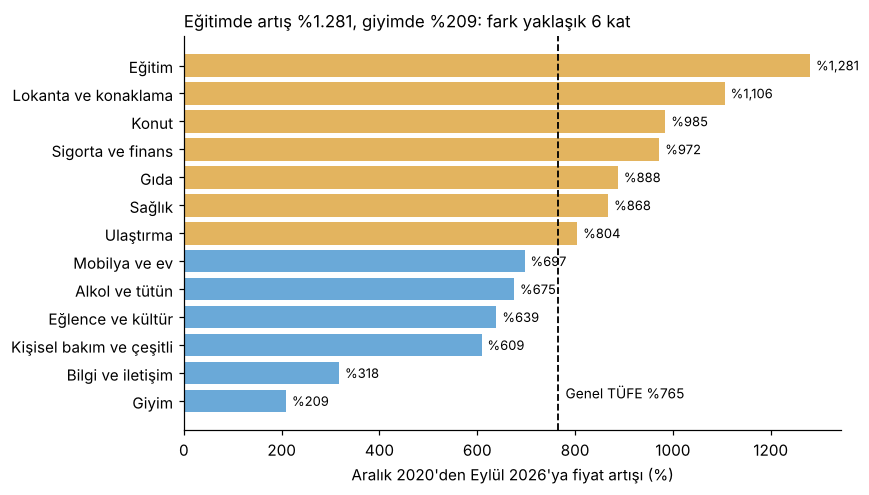

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.6))
renk = [UP if v > GEN else DOWN for v in tablo["artis_yuzde"]]
ax.barh(tablo["grup_kisa_ad"][::-1], tablo["artis_yuzde"][::-1], color=renk[::-1])
ax.axvline(GEN, color="k", ls="--", lw=1.2); ax.text(GEN + 15, 0.1, f"Genel TÜFE %{GEN:,.0f}", fontsize=9)
for y, v in enumerate(tablo["artis_yuzde"][::-1]): ax.text(v + 12, y, f"%{v:,.0f}", va="center", fontsize=8.5)
ax.set_xlabel("Aralık 2020'den Eylül 2026'ya fiyat artışı (%)")
ax.set_title("Eğitimde artış %1.281, giyimde %209: fark yaklaşık 6 kat", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

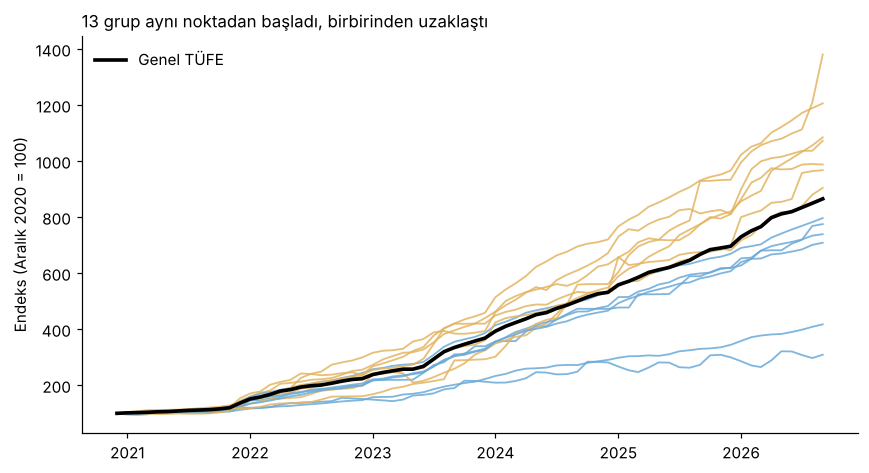

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for k in reb.columns:
    if k == "0": continue
    ax.plot(pd.to_datetime(reb.index), reb[k], color=UP if g.loc[k, "artis_yuzde"] > GEN else DOWN, lw=1.2, alpha=.85)
ax.plot(pd.to_datetime(reb.index), reb["0"], color="k", lw=2.4, label="Genel TÜFE")
ax.set_ylabel("Endeks (Aralık 2020 = 100)"); ax.legend(frameon=False, loc="upper left")
ax.set_title("13 grup aynı noktadan başladı, birbirinden uzaklaştı", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

### Ağırlık: artışlar sepette ne kadar yer tutuyor?

In [9]:
ust = tablo[tablo["ortalamanin"] == "üstünde"]; alt = tablo[tablo["ortalamanin"] == "altında"]
print(f"Ortalamanın üstünde artan grup sayısı: {len(ust)}, altında: {len(alt)}")
print(f"Üstünde artan grupların sepet payı: %{ust['agirlik_yuzde_2026'].sum():.1f}")
print(f"Altında kalan grupların sepet payı: %{alt['agirlik_yuzde_2026'].sum():.1f}")
print(f"Gıda + konut sepet payı: %{tablo.loc[['01','04'], 'agirlik_yuzde_2026'].sum():.1f}")
print(f"Giyim + bilgi/iletişim sepet payı: %{tablo.loc[['03','08'], 'agirlik_yuzde_2026'].sum():.1f}")
print(f"En çok / en az artan oranı: {tablo['artis_yuzde'].max() / tablo['artis_yuzde'].min():.2f}")

# Bilgi: 2026 ağırlıklarıyla grup artışlarının ortalaması genel endeksle birebir aynı değildir
agirlikli = (tablo["agirlik_yuzde_2026"] * tablo["artis_yuzde"]).sum() / tablo["agirlik_yuzde_2026"].sum()
print(f"\n2026 ağırlıklarıyla grup artışlarının ortalaması: %{agirlikli:.1f} | genel TÜFE: %{GEN:.1f}")

Ortalamanın üstünde artan grup sayısı: 7, altında: 6
Üstünde artan grupların sepet payı: %69.5
Altında kalan grupların sepet payı: %30.5
Gıda + konut sepet payı: %35.8
Giyim + bilgi/iletişim sepet payı: %11.0
En çok / en az artan oranı: 6.13

2026 ağırlıklarıyla grup artışlarının ortalaması: %801.9 | genel TÜFE: %765.3


Genel endeks zincirleme hesaplandığı için 2026 ağırlıklarıyla alınan basit ortalama genel TÜFE'ye birebir eşit çıkmaz (yukarıdaki iki sayı farklı). Sitede ağırlıklar yalnızca **bugünkü sepeti** anlatmak için kullanılıyor, geçmiş yıllar için kullanılmıyor.

In [10]:
# Yıllık enflasyon: sitedeki bağlam paragrafındaki iki rakam
yillik = lambda a, b: p.loc[a, "0"] / p.loc[b, "0"] * 100 - 100
print(f"Eylül 2024 yıllık TÜFE: %{yillik('2024-09', '2023-09'):.2f}  (TÜİK'in yayımladığı: %49,38, fark yuvarlamadan)")
print(f"Eylül 2026 yıllık TÜFE: %{yillik('2026-09', '2025-09'):.2f}")
assert abs(yillik('2024-09', '2023-09') - 49.38) < 0.02 and abs(yillik('2026-09', '2025-09') - 29.73) < 0.02

Eylül 2024 yıllık TÜFE: %49.39  (TÜİK'in yayımladığı: %49,38, fark yuvarlamadan)
Eylül 2026 yıllık TÜFE: %29.73


## 4. Bulgular

1. Genel fiyat düzeyi Aralık 2020'den Eylül 2026'ya yaklaşık **8,65 katına** çıktı (%765).
2. En çok artanlar **eğitim hizmetleri (%1.281)**, **lokantalar ve konaklama (%1.106)** ve **konut (%985)**. En az artanlar **giyim (%209)** ve **bilgi ve iletişim (%318)**.
3. 13 grubun **7'si ortalamanın üstünde, 6'sı altında**. En çok artan, en az artanın yaklaşık **6 katı** kadar arttı.
4. Ortalamanın üstünde artan gruplar bugünkü sepetin yaklaşık **%69,5'ini** oluşturuyor; en geride kalan giyim ve iletişim yalnızca yaklaşık **%11'ini**.
5. Bu çalışma yalnızca **ilişkiyi** gösterir. Fiyatların neden farklı hızda arttığı (maliyet, talep, kur) bu veriyle açıklanamaz.

## 5. Doğrulama

Endekslerden yeniden hesapladığımız Eylül 2026 değişimlerini kontrol tablosuyla karşılaştırıyoruz. Endeksler 4 ondalığa yuvarlı olduğu için küçük yuvarlama farkları beklenir.

In [11]:
c = chk.set_index("grup_kodu")
hesap = pd.DataFrame({
    "yillik_degisim_eylul2026": (p.loc["2026-09"] / p.loc["2025-09"] * 100 - 100),
    "yilbasi_degisim_eylul2026": (p.loc["2026-09"] / p.loc["2025-12"] * 100 - 100),
    "aylik_degisim_eylul2026": (p.loc["2026-09"] / p.loc["2026-08"] * 100 - 100),
})
fark = (hesap - c[hesap.columns]).abs()
print("En büyük mutlak fark (puan):")
print(fark.max().round(4).to_string())
assert fark.max().max() < 0.01
print("\nTüm değişimler kontrol tablosuyla 0,01 puan içinde örtüşüyor.")

En büyük mutlak fark (puan):
yillik_degisim_eylul2026     0.0048
yilbasi_degisim_eylul2026    0.0048
aylik_degisim_eylul2026      0.0047

Tüm değişimler kontrol tablosuyla 0,01 puan içinde örtüşüyor.


## 6. Sitede kullanılan özet dosyaların üretimi

Site yalnızca bu iki özet dosyayı (ve 2005–2026 tam seriyi) okur; ham veri sitede kullanılmaz. Toplam boyut 5 MB'ın çok altındadır.

In [12]:
names = idx[["grup_kodu", "grup_adi", "grup_kisa_ad"]].drop_duplicates().set_index("grup_kodu")

# 1) 2020-12 → 2026-09 endeks tablosu (hem 2025=100 hem Aralık 2020=100)
e = idx[idx["tarih"] >= BASE].copy()
e["endeks_aralik2020_100"] = [reb.loc[t, k] for t, k in zip(e["tarih"], e["grup_kodu"])]
e["endeks_aralik2020_100"] = e["endeks_aralik2020_100"].round(4)
e = e[["tarih", "grup_kodu", "grup_adi", "grup_kisa_ad", "endeks_2025_100", "endeks_aralik2020_100"]]

# 2) grup özet tablosu
o = names.join(w.set_index("grup_kodu")[["agirlik_yuzde_2026"]])
o["artis_aralik2020_eylul2026_yuzde"] = (reb.iloc[-1] - 100).round(2)
o = o.join(hesap.round(2))
o["endeks_eylul2026"] = p.loc["2026-09"].round(2)
o["genel_tufeden_fark_puan"] = ((reb.iloc[-1] - 100) - (reb.iloc[-1]["0"] - 100)).round(1)
o = o.reset_index()[["grup_kodu", "grup_adi", "grup_kisa_ad", "agirlik_yuzde_2026", "artis_aralik2020_eylul2026_yuzde",
                     "yillik_degisim_eylul2026", "yilbasi_degisim_eylul2026", "aylik_degisim_eylul2026",
                     "endeks_eylul2026", "genel_tufeden_fark_puan"]]

for d in OUT:
    d.mkdir(parents=True, exist_ok=True)
    e.to_csv(d / "tufe_endeks_aylik_2020-2026.csv", index=False, lineterminator="\n")
    o.to_csv(d / "gruplar_ozet_eylul2026.csv", index=False, lineterminator="\n")
    idx.to_csv(d / "tufe_endeks_aylik_2005-2026.csv", index=False, lineterminator="\n")
print("Yazıldı:", [str(d) for d in OUT])
print("endeks_2020-2026:", e.shape, "| özet:", o.shape)
size = sum(f.stat().st_size for f in OUT[1].glob("*.csv"))
print(f"Site veri dosyalarının toplam boyutu: {size/1024:.0f} KB (sınır 5 MB)")
assert size < 5 * 1024 * 1024
o.round(2)

Yazıldı: ['../data/processed', '../site/data']
endeks_2020-2026: (980, 6) | özet: (14, 10)
Site veri dosyalarının toplam boyutu: 308 KB (sınır 5 MB)


,grup_kodu,grup_adi,grup_kisa_ad,agirlik_yuzde_2026,artis_aralik2020_eylul2026_yuzde,yillik_degisim_eylul2026,yilbasi_degisim_eylul2026,aylik_degisim_eylul2026,endeks_eylul2026,genel_tufeden_fark_puan
0,0,TÜFE,Genel TÜFE,100.00,765.35,29.73,24.32,1.84,137.23,0.0
1,01,Gıda ve alkolsüz içecekler,Gıda,24.44,887.68,27.62,21.84,-0.20,134.04,122.3
2,02,"Alkollü içecekler, tütün ve tütün ürünleri",Alkol ve tütün,2.75,675.23,31.60,25.39,0.88,140.34,-90.1
3,03,Giyim ve ayakkabı,Giyim,7.90,209.05,13.22,3.06,3.98,112.06,-556.3
4,04,"Konut, su, elektrik, gaz ve diğer yakıtlar",Konut,11.40,984.60,39.99,32.26,2.71,152.10,219.3
5,05,"Mobilya, mefruşat ve evde kullanılan ekipmanla...",Mobilya ve ev,7.92,696.73,23.81,19.09,1.83,128.81,-68.6
6,06,Sağlık,Sağlık,2.79,867.66,43.26,38.90,0.35,146.58,102.3
7,07,Ulaştırma,Ulaştırma,16.62,804.37,35.10,32.73,2.79,144.05,39.0
8,08,Bilgi ve iletişim,Bilgi ve iletişim,3.10,317.50,26.51,21.24,2.16,131.26,-447.8
9,09,"Eğlence, dinlence, spor ve kültür",Eğlence ve kültür,4.34,639.18,23.36,19.26,0.72,129.49,-126.2


## 7. Sınırlılıklar

- TÜFE **ortalama bir hane** için hesaplanır; kişisel enflasyon farklı olabilir.
- Ağırlıklar yalnızca 2026'ya aittir; geçmiş yıllarda paylar farklıydı.
- Analiz **betimleyicidir**: hangi kalemlerin hızlı arttığını gösterir, nedenini göstermez.
- Başlangıç ayı seçimi (Aralık 2020) sıralamayı etkileyebilir; site bu yüzden okuyucuya başlangıç ve bitiş ayını seçtirir.